# Chapter 7 — Unsupervised Learning

**Buku:** Practical Statistics for Data Scientists, 2nd Edition — Peter Bruce, Andrew Bruce, Peter Gedeck (2020)

Notebook ini membahas subtopik utama Bab 7 secara berurutan melalui penjelasan teori, implementasi Python, visualisasi, dan interpretasi hasil. Data demonstrasi menggunakan dataset bawaan atau data sintetis sehingga dapat dijalankan secara mandiri di Google Colab.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
np.set_printoptions(precision=3, suppress=True)
RANDOM_STATE=42

## 1. Introduction to unsupervised learning

Unsupervised learning uses observations without an explicit response label. Clustering searches for groups of similar cases, while dimension reduction attempts to represent the same information using fewer variables.

In [2]:
from sklearn.datasets import load_wine
wine=load_wine(as_frame=True)
X=wine.data
print('Observations:',X.shape[0], 'Numeric predictors:',X.shape[1])
print(X.iloc[:4,:5].round(2).to_string())

Observations: 178 Numeric predictors: 13
   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium
0    14.23        1.71  2.43               15.6      127.0
1    13.20        1.78  2.14               11.2      100.0
2    13.16        2.36  2.67               18.6      101.0
3    14.37        1.95  2.50               16.8      113.0


**Interpretasi.** Hasil memperlihatkan 178 observasi dengan 13 variabel. Target dataset sengaja tidak dipakai untuk melatih metode unsupervised. Informasi label nantinya hanya dapat dipakai sebagai pembanding eksternal, bukan dasar pembentukan klaster.

## 2. Preparing the feature matrix

Before PCA or distance-based clustering, each numeric variable should be checked for missing data and scale differences. Features with much larger variances can dominate the result.

In [3]:
from sklearn.preprocessing import StandardScaler
print('Missing values:',int(X.isna().sum().sum()))
print(X.agg(['mean','std']).iloc[:,:6].round(2).to_string())
Z=StandardScaler().fit_transform(X)
print('Standardized means:',np.round(Z.mean(axis=0)[:4],3))

Missing values: 0
      alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols
mean    13.00        2.34  2.37              19.49      99.74           2.30
std      0.81        1.12  0.27               3.34      14.28           0.63
Standardized means: [-0. -0. -0. -0.]


**Interpretasi.** Perbedaan rata-rata dan simpangan baku antarvariabel menunjukkan alasan standarisasi. Setelah standardisasi, setiap variabel mendekati rerata nol dan simpangan baku satu sehingga PCA dan algoritma berbasis jarak tidak berat sebelah.

## 3. Principal Components Analysis: simple example

PCA creates orthogonal directions that capture the largest variance in a dataset. Its purpose is compression of numerical features, rather than direct classification.

In [4]:
from sklearn.decomposition import PCA
pca=PCA(n_components=2)
P=pca.fit_transform(Z)
print('Original dimensions:',Z.shape,'PCA dimensions:',P.shape)
print('Explained variance ratios:',pca.explained_variance_ratio_.round(3))

Original dimensions: (178, 13) PCA dimensions: (178, 2)
Explained variance ratios: [0.362 0.192]


**Interpretasi.** Dua komponen pertama merangkum sebagian variasi seluruh 13 fitur. Persentase explained variance mengukur informasi variasi yang dipertahankan; angka ini tidak sama dengan akurasi klasifikasi.

## 4. PCA: projection of observations

A two-dimensional scatterplot of principal components can help detect concentration, spread, and separation of observations. Color by known class is added only as an external interpretation aid.

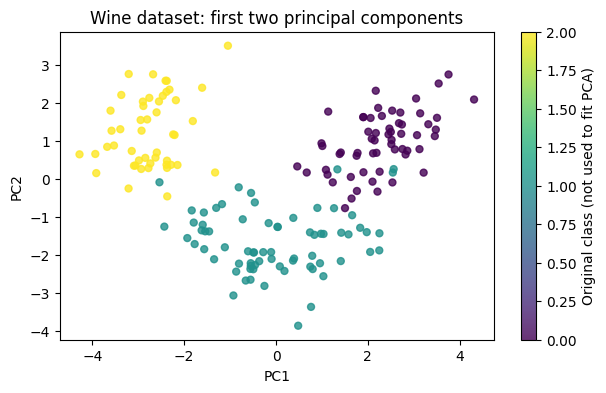

In [5]:
plt.figure(figsize=(7,4))
plt.scatter(P[:,0],P[:,1],c=wine.target,cmap='viridis',s=25,alpha=.8)
plt.xlabel('PC1');plt.ylabel('PC2');plt.title('Wine dataset: first two principal components');plt.colorbar(label='Original class (not used to fit PCA)');plt.show()

**Interpretasi.** Grafik menunjukkan bagaimana observasi terdistribusi pada dua sumbu baru. Jika warna kelas cenderung mengelompok, itu menunjukkan struktur yang dapat terlihat melalui PCA, tetapi PCA sendiri tidak menggunakan label kelas.

## 5. Computing principal components with SVD

Singular value decomposition gives a matrix factorization related to PCA. Comparing the first component from PCA and the singular vectors illustrates this underlying connection.

In [6]:
U,S,Vt=np.linalg.svd(Z,full_matrices=False)
print('First five singular values:',S[:5].round(3))
print('First component direction agreement:',round(abs(np.dot(Vt[0],pca.components_[0])),5))

First five singular values: [28.942 21.082 16.044 12.79  12.324]
First component direction agreement: 1.0


**Interpretasi.** Kesepakatan arah mendekati satu menunjukkan PCA dan SVD menghasilkan arah principal component yang sebanding. Tanda positif atau negatif tidak penting karena arah komponen dapat dibalik tanpa mengubah proyeksi substansial.

## 6. Interpreting principal component loadings

Component loadings show which original variables contribute most strongly to each component. Large absolute weights matter more than the positive or negative sign alone.

In [7]:
loadings=pd.DataFrame(pca.components_.T,index=X.columns,columns=['PC1','PC2'])
print(loadings.reindex(loadings.PC1.abs().sort_values(ascending=False).index).head(8).round(3).to_string())

                                PC1    PC2
flavanoids                    0.423 -0.003
total_phenols                 0.395  0.065
od280/od315_of_diluted_wines  0.376 -0.164
proanthocyanins               0.313  0.039
nonflavanoid_phenols         -0.299  0.029
hue                           0.297 -0.279
proline                       0.287  0.365
malic_acid                   -0.245  0.225


**Interpretasi.** Variabel dengan loading absolut terbesar paling berpengaruh terhadap PC1. Hubungan tanda harus dibaca bersama arah komponen; pembalikan tanda tidak mengubah kualitas PCA.

## 7. Choosing principal components with a scree plot

The cumulative explained variance helps decide how many components to keep for further analysis. A common heuristic is to preserve a target proportion of variance.

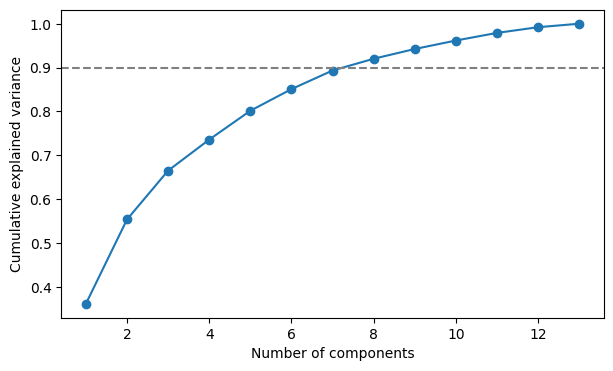

Components for >=90% variance: 8


In [8]:
full=PCA().fit(Z)
cumulative=np.cumsum(full.explained_variance_ratio_)
plt.figure(figsize=(7,4));plt.plot(range(1,len(cumulative)+1),cumulative,'o-');plt.axhline(.9,ls='--',color='gray');plt.xlabel('Number of components');plt.ylabel('Cumulative explained variance');plt.show()
print('Components for >=90% variance:',np.searchsorted(cumulative,.9)+1)

**Interpretasi.** Kurva kumulatif naik hingga mendekati 100%. Jumlah komponen minimum untuk mempertahankan 90% variasi memberi kompromi antara pengurangan dimensi dan hilangnya informasi.

## 8. PCA reconstruction error

Compression can be checked by projecting standardized data to fewer dimensions and reconstructing it. More components usually reduce reconstruction error.

In [9]:
for k in [2,4,8,12]:
 m=PCA(n_components=k).fit(Z);Zhat=m.inverse_transform(m.transform(Z))
 print(f'{k:2d} components | MSE: {np.mean((Z-Zhat)**2):.4f}')

 2 components | MSE: 0.4459
 4 components | MSE: 0.2640
 8 components | MSE: 0.0798
12 components | MSE: 0.0080


**Interpretasi.** Reconstruction MSE cenderung menurun jika lebih banyak komponen disimpan. Dua komponen memudahkan visualisasi, tetapi belum tentu mempertahankan cukup informasi untuk penggunaan prediktif.

## 9. Correspondence analysis: contingency structure

Correspondence analysis applies a geometric representation to categorical frequency tables. The standardized residual matrix highlights departures from independence before applying SVD.

In [10]:
table=pd.DataFrame([[30,10,5],[10,25,15],[5,10,30]],index=['Segment A','Segment B','Segment C'],columns=['Choice X','Choice Y','Choice Z'])
F=table.to_numpy()/table.to_numpy().sum()
r=F.sum(axis=1);c=F.sum(axis=0)
S=(F-np.outer(r,c))/np.sqrt(np.outer(r,c))
u,s,vt=np.linalg.svd(S,full_matrices=False)
print('Singular values:',s.round(4));print('Row coordinate sample:',np.round((u[:,:2]*s[:2])/np.sqrt(r[:,None]),3))

Singular values: [0.547 0.282 0.   ]
Row coordinate sample: [[-0.741  0.149]
 [ 0.122 -0.373]
 [ 0.605  0.266]]


**Interpretasi.** Tabel frekuensi menunjukkan hubungan segmen dan pilihan. Nilai singular terbesar menunjukkan struktur asosiasi yang melampaui pola independensi sederhana. Ini demonstrasi mekanika dasar, bukan implementasi lengkap perangkat correspondence analysis.

## 10. K-means: a simple clustering example

K-means partitions observations into k groups by minimizing within-cluster squared Euclidean distances. Its centroids summarize the average position of each cluster.

In [11]:
from sklearn.cluster import KMeans
km=KMeans(n_clusters=3,n_init=10,random_state=42).fit(Z)
print('Cluster sizes:',np.bincount(km.labels_));print('Inertia:',round(km.inertia_,2))

Cluster sizes: [65 51 62]
Inertia: 1277.93


**Interpretasi.** Ukuran klaster menunjukkan sebaran observasi hasil pengelompokan. Inertia adalah total jarak kuadrat terhadap centroid masing-masing; angka lebih kecil tidak otomatis berarti jumlah klaster yang lebih baik tanpa mempertimbangkan kompleksitas.

## 11. K-means cluster centers

Centroids can be inspected on the standardized scale to understand which measurements distinguish each group. A feature-level profile is often more informative than cluster labels alone.

In [12]:
centers=pd.DataFrame(km.cluster_centers_,columns=X.columns)
print(centers[['alcohol','malic_acid','color_intensity','proline']].round(2).to_string())

   alcohol  malic_acid  color_intensity  proline
0    -0.93       -0.39            -0.90    -0.75
1     0.16        0.87             0.94    -0.41
2     0.84       -0.30             0.17     1.13


**Interpretasi.** Rata-rata z-score yang positif menunjukkan fitur di atas rata-rata keseluruhan, sedangkan nilai negatif menunjukkan di bawah rata-rata. Nomor klaster tidak mempunyai urutan atau makna intrinsik.

## 12. Visualizing the K-means assignments

PCA is useful for displaying clusters that were learned from the full standardized dataset; the visualization itself is not the clustering objective.

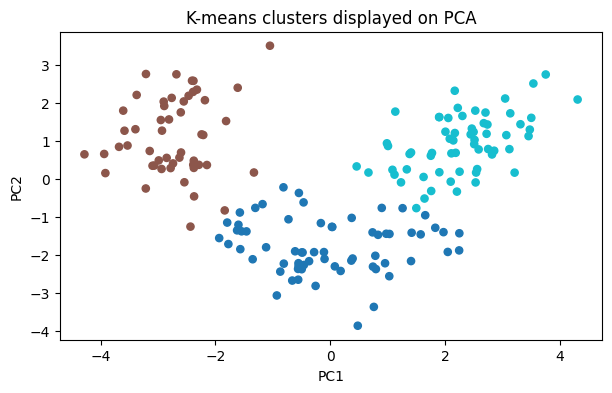

In [13]:
plt.figure(figsize=(7,4));plt.scatter(P[:,0],P[:,1],c=km.labels_,cmap='tab10',s=27)
plt.xlabel('PC1');plt.ylabel('PC2');plt.title('K-means clusters displayed on PCA');plt.show()

**Interpretasi.** Pemisahan warna di plot memberi gambaran kasar tentang kelompok, tetapi jarak pada dua komponen tidak sepenuhnya mewakili jarak pada 13 fitur yang dipakai K-means.

## 13. Selecting the number of clusters: elbow method

The elbow method compares inertia across different values of k. The preferred solution balances reduced within-cluster variation and a reasonable number of clusters.

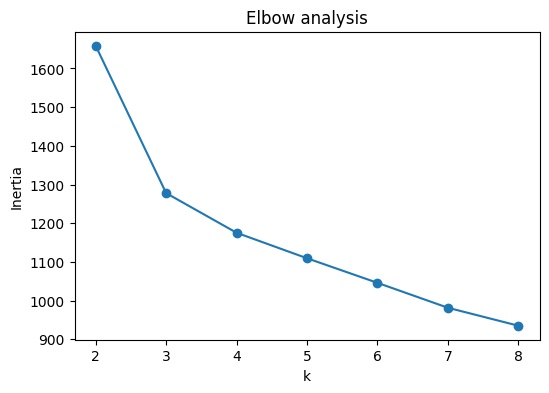

In [14]:
ks=list(range(2,9));inertias=[KMeans(n_clusters=k,n_init=10,random_state=42).fit(Z).inertia_ for k in ks]
plt.figure(figsize=(6,4));plt.plot(ks,inertias,'o-');plt.xlabel('k');plt.ylabel('Inertia');plt.title('Elbow analysis');plt.show()

**Interpretasi.** Inertia selalu tidak meningkat ketika k bertambah; karena itu nilai paling kecil saja bukan kriteria yang cukup. Perhatikan perubahan kemiringan kurva dan interpretabilitas klaster.

## 14. Silhouette analysis for K-means

Silhouette score combines cohesion and separation, ranging from -1 to 1. Higher average values generally indicate better separated groups for the chosen distance.

In [15]:
from sklearn.metrics import silhouette_score
for k in range(2,7):
 labels=KMeans(n_clusters=k,n_init=10,random_state=42).fit_predict(Z)
 print(k,round(silhouette_score(Z,labels),3))

2 0.259
3 0.285
4 0.26
5 0.202
6 0.237


**Interpretasi.** Skor silhouette berbeda menurut jumlah klaster. Nilai positif yang lebih tinggi biasanya mendukung pengelompokan yang lebih jelas, namun interpretasi domain tetap diperlukan.

## 15. Hierarchical clustering and agglomeration

Agglomerative clustering begins with individual observations and repeatedly combines groups. The linkage rule determines which pair of clusters is merged next.

In [16]:
from sklearn.cluster import AgglomerativeClustering
for linkage in ['ward','complete','average','single']:
 lab=AgglomerativeClustering(n_clusters=3,linkage=linkage).fit_predict(Z)
 print(linkage, 'sizes:',np.bincount(lab),'silhouette:',round(silhouette_score(Z,lab),3))

ward sizes: [58 56 64] silhouette: 0.277
complete sizes: [69 58 51] silhouette: 0.204
average sizes: [174   1   3] silhouette: 0.158
single sizes: [174   3   1] silhouette: 0.183


**Interpretasi.** Perbedaan linkage mengubah bentuk kelompok karena tiap aturan mendefinisikan kedekatan klaster secara berbeda. Ward cenderung mengutamakan kelompok yang kompak; single linkage lebih mudah membentuk rangkaian panjang.

## 16. Reading a dendrogram

The dendrogram depicts the sequence and merge distance of hierarchical clustering. It can suggest plausible cuts without assuming a single optimal k.

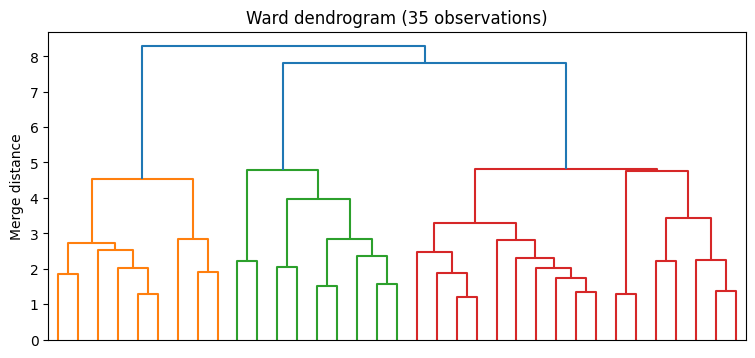

In [17]:
from scipy.cluster.hierarchy import linkage,dendrogram
L=linkage(Z[:35],method='ward')
plt.figure(figsize=(9,4));dendrogram(L,no_labels=True);plt.ylabel('Merge distance');plt.title('Ward dendrogram (35 observations)');plt.show()

**Interpretasi.** Cabang yang menyatu pada ketinggian besar menandakan kelompok relatif berjauhan. Memotong dendrogram pada ketinggian tertentu menghasilkan jumlah kelompok yang bergantung pada batas tersebut.

## 17. Distance measures and cluster structure

Clustering results depend on distance. Euclidean distance measures straight-line displacement, whereas Manhattan distance sums absolute coordinate differences.

In [18]:
from sklearn.metrics import pairwise_distances
a=Z[:3,:4]
print('Euclidean:\n',np.round(pairwise_distances(a,metric='euclidean'),2))
print('Manhattan:\n',np.round(pairwise_distances(a,metric='manhattan'),2))

Euclidean:
 [[0.   2.12 1.92]
 [2.12 0.   2.99]
 [1.92 2.99 0.  ]]
Manhattan:
 [[0.   3.72 3.68]
 [3.72 0.   4.73]
 [3.68 4.73 0.  ]]


**Interpretasi.** Matriks jarak memiliki diagonal nol dan bersifat simetris. Pilihan metrik memengaruhi kedekatan data, terutama jika banyak variabel atau outlier hadir.

## 18. Model-based clustering with Gaussian mixtures

Gaussian mixture models represent the dataset as a weighted sum of probability distributions, allowing elliptical clusters and soft assignment probabilities.

In [19]:
from sklearn.mixture import GaussianMixture
gmm=GaussianMixture(n_components=3,random_state=42,n_init=3).fit(Z)
prob=gmm.predict_proba(Z[:5]);print('First five membership probabilities:\n',np.round(prob,3))
print('Component weights:',np.round(gmm.weights_,3))

First five membership probabilities:
 [[1. 0. 0.]
 [1. 0. 0.]
 [1. 0. 0.]
 [1. 0. 0.]
 [1. 0. 0.]]
Component weights: [0.356 0.358 0.286]


**Interpretasi.** Setiap baris probabilitas berjumlah sekitar satu dan menunjukkan tingkat keanggotaan pada komponen, tidak hanya label tunggal. Komponen campuran tidak selalu sama dengan kelompok nyata yang secara substantif bermakna.

## 19. Gaussian mixtures: covariance assumptions

A Gaussian mixture may use full, diagonal, tied, or spherical covariance structures. These assumptions affect the flexibility of cluster shapes and required parameters.

In [20]:
for cov in ['full','tied','diag','spherical']:
 m=GaussianMixture(n_components=3,covariance_type=cov,random_state=42,n_init=2).fit(Z)
 print(cov, 'BIC:',round(m.bic(Z),1))

full BIC: 5829.4


tied BIC: 5572.6
diag BIC: 5556.8


spherical BIC: 5708.8


**Interpretasi.** Model yang lebih fleksibel dapat lebih cocok pada data pelatihan, tetapi juga menambah kompleksitas. BIC memberi penalti pada jumlah parameter sehingga berguna saat membandingkan struktur kovarians.

## 20. Selecting the number of Gaussian mixture components

Information criteria such as BIC and AIC trade goodness of fit against complexity. Lower values are preferred for comparisons on the same dataset.

In [21]:
for k in range(1,7):
 m=GaussianMixture(n_components=k,covariance_type='diag',random_state=42,n_init=2).fit(Z)
 print(f'k={k}: BIC={m.bic(Z):.1f}, AIC={m.aic(Z):.1f}')

k=1: BIC=6701.6, AIC=6618.8
k=2: BIC=5983.7, AIC=5815.1
k=3: BIC=5556.8, AIC=5302.3
k=4: BIC=5556.6, AIC=5216.1
k=5: BIC=5544.7, AIC=5118.3


k=6: BIC=5560.9, AIC=5048.6


**Interpretasi.** BIC dan AIC tidak harus memilih jumlah komponen yang sama. Keduanya mengukur kecocokan probabilistik dan kompleksitas, bukan kebenaran kategori eksternal.

## 21. Scaling variables changes clustering

A distance-based algorithm can be dominated by high-variance columns. Comparing raw-data and scaled-data assignments illustrates the practical consequences.

In [22]:
from sklearn.metrics import adjusted_rand_score
raw=KMeans(n_clusters=3,n_init=10,random_state=42).fit_predict(X)
scaled=km.labels_
print('Agreement between raw and scaled K-means (ARI):',round(adjusted_rand_score(raw,scaled),3))

Agreement between raw and scaled K-means (ARI): 0.354


**Interpretasi.** Jika ARI rendah, perubahan skala mengubah pembagian kelompok secara nyata. Hal ini menegaskan bahwa standarisasi bukan hanya kosmetik, melainkan keputusan pemodelan yang harus didokumentasikan.

## 22. Categorical data and Gower-style distance

For mixed numerical and categorical data, standard Euclidean distance is not sufficient. A simplified Gower-style dissimilarity averages normalized numerical differences and categorical mismatches.

In [23]:
mix=pd.DataFrame({'age':[22,30,24,45], 'spend':[10,40,13,50], 'region':['A','A','B','B']})
num=mix[['age','spend']];norm=(num-num.min())/(num.max()-num.min())
D=np.zeros((len(mix),len(mix)))
for i in range(len(mix)):
 for j in range(len(mix)):
  D[i,j]=(abs(norm.iloc[i]-norm.iloc[j]).sum()+int(mix.region.iloc[i]!=mix.region.iloc[j]))/3
print(np.round(D,3))

[[0.    0.366 0.387 1.   ]
 [0.366 0.    0.645 0.634]
 [0.387 0.645 0.    0.613]
 [1.    0.634 0.613 0.   ]]


**Interpretasi.** Nilai jarak nol menunjukkan observasi yang identik dan nilai lebih besar menandakan perbedaan lebih kuat. Rumus sederhana ini hanya demonstrasi untuk data lengkap; Gower lengkap perlu menangani tipe data dan missing values lebih teliti.

## 23. Challenges of clustering mixed data

The relative weight of numeric and categorical attributes changes pairwise distances. Inspecting cluster sizes and distances is necessary before interpreting segments.

In [24]:
from sklearn.cluster import AgglomerativeClustering
labels=AgglomerativeClustering(n_clusters=2,linkage='average',metric='precomputed').fit_predict(D)
print(pd.DataFrame({'region':mix.region,'cluster':labels,'age':mix.age,'spend':mix.spend}).to_string(index=False))

region  cluster  age  spend
     A        0   22     10
     A        0   30     40
     B        0   24     13
     B        1   45     50


**Interpretasi.** Kelompok hasil perhitungan hanya berdasarkan kemiripan atribut yang dipilih dan bobotnya. Dengan empat observasi, hasil bersifat ilustratif dan belum layak dijadikan segmentasi populasi yang stabil.